# STEP 1 - DATA COLLECTION AND INGESTION

In [79]:
import os
import pandas as pd
import numpy as np
import random
import json
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r'C:\Users\Kayode Ogunyemi\Downloads\teleconnect.csv'
OUTPUT_DIR = "baseline_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Verify and load the dataset
if not os.path.exists(file_path):
    raise FileNotFoundError(f"Dataset not found: {file_path}")

dataset = pd.read_csv(file_path)
#dataset.columns = dataset.columns.str.strip()
print("File exists:", os.path.exists(file_path))
print("Dataset shape:", dataset.shape)

## Rename so we can use DF everywhere else
df = dataset.copy()
df.head()



File exists: True
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [80]:
##### **Data Validation - Inspection of the Teleconnect.csv dataset provided**
## Reviewed all the 21 Columns in the Dataset

#Summary
print("\nDATASET OVERVIEW")
print("-" * 50)
print("Shape:", df.shape)
print("\n\n")
print("\nCHURN DISTRIBUTION:")
print("-" * 50)
print(df["Churn"].value_counts(dropna=False))

# Convert blank strings and whitespace to NaN
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", pd.NA, regex=True)

# Check missing values
missing_count = df["TotalCharges"].isna().sum()
total_records = len(df)
missing_percentage = (missing_count / total_records) * 100
print("\n\n")
print("TOTALCHARGES - Missing Value Analysis")
print("-" * 40)
print(f"Total records       : {total_records}")
print(f"Missing values      : {missing_count}")
print(f"Non-missing values  : {total_records - missing_count}")
print(f"Missing percentage : {missing_percentage:.2f}%")

# Display rows with missing TotalCharges
missing_rows = df[df["TotalCharges"].isna()]
print("\n\n")
print("\nRows with missing TOTALCHARGES:")
print("-" * 50)
print(missing_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])




DATASET OVERVIEW
--------------------------------------------------
Shape: (7043, 21)




CHURN DISTRIBUTION:
--------------------------------------------------
Churn
No     5174
Yes    1869
Name: count, dtype: int64



TOTALCHARGES - Missing Value Analysis
----------------------------------------
Total records       : 7043
Missing values      : 11
Non-missing values  : 7032
Missing percentage : 0.16%




Rows with missing TOTALCHARGES:
--------------------------------------------------
      customerID  tenure  MonthlyCharges TotalCharges
488   4472-LVYGI       0           52.55          NaN
753   3115-CZMZD       0           20.25          NaN
936   5709-LVOEQ       0           80.85          NaN
1082  4367-NUYAO       0           25.75          NaN
1340  1371-DWPAZ       0           56.05          NaN
3331  7644-OMVMY       0           19.85          NaN
3826  3213-VVOLG       0           25.35          NaN
4380  2520-SGTTA       0           20.00          NaN
5218  2923-ARZLG     

# STEP2 - DATA CLEANING

In [81]:

## Check if the Target exits
TARGET = "Churn"
if TARGET not in df.columns:
    raise ValueError(f"Target '{TARGET}' not found. "f"Available columns: {df.columns.tolist()}")

# Standardize target labels.
y_raw = df[TARGET].astype("string").str.strip().str.lower()
y = y_raw.map({"yes": 1, "no": 0})

if y.isnull().any():
    invalid = y_raw[y.isnull()].unique().tolist()
    raise ValueError(f"Unexpected Churn labels: {invalid}")

if y.nunique() != 2:
    raise ValueError("Churn must contain both binary classes.")



# Exclude target and customer identifier from model features.
X = df.drop(columns=[TARGET])
X = X.drop(columns=["customerID"], errors="ignore")


# Convert TotalCharges to numeric when present.
if "TotalCharges" in X.columns:
    X["TotalCharges"] = pd.to_numeric(X["TotalCharges"], errors="coerce")


# Convert boolean columns to categorical strings.
for column in X.select_dtypes(include=["bool"]).columns:
    X[column] = X[column].astype("string")



# STEP2B - FEATURE ANALYSIS

In [5]:
import pandas as pd
import numpy as np

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Overall churn distribution
churn_summary = (
    df.groupby("Churn")
      .size()
      .reset_index(name="customers")
)

churn_summary["percentage"] = (
    churn_summary["customers"] / len(df) * 100
).round(2)

display(churn_summary)

# Churn rates for important segmentation features
features = [
    "Contract",
    "tenure",
    "InternetService",
    "PaymentMethod",
    "MonthlyCharges",
    "TechSupport",
    "OnlineSecurity",
    "SeniorCitizen",
]

# Group continuous variables into interpretable bands
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "49-72 months"]
)

df["monthly_charges_group"] = pd.cut(
    df["MonthlyCharges"],
    bins=[-np.inf, 35, 70, np.inf],
    labels=["Low", "Medium", "High"]
)

analysis_features = [
    "Contract",
    "tenure_group",
    "InternetService",
    "PaymentMethod",
    "monthly_charges_group",
    "TechSupport",
    "OnlineSecurity",
    "SeniorCitizen",
]

for feature in analysis_features:
    summary = (
        df.groupby(feature, observed=True, dropna=False)["Churn"]
          .agg(
              customers="size",
              churn_rate=lambda s: (
                  s.astype(str).str.strip().str.lower().eq("yes").mean()
                  * 100
              )
          )
          .reset_index()
    )

    summary["churn_rate"] = summary["churn_rate"].round(2)

    print(f"\nChurn analysis by {feature}")
    display(summary.sort_values("churn_rate", ascending=False))

,Churn,customers,percentage
0,No,5174,73.46
1,Yes,1869,26.54



Churn analysis by Contract


,Contract,customers,churn_rate
0,Month-to-month,3875,42.71
1,One year,1473,11.27
2,Two year,1695,2.83



Churn analysis by tenure_group


,tenure_group,customers,churn_rate
0,0-12 months,2186,47.44
1,13-24 months,1024,28.71
2,25-48 months,1594,20.39
3,49-72 months,2239,9.51


...

,TechSupport,customers,churn_rate
0,No,3473,41.64
2,Yes,2044,15.17
1,No internet service,1526,7.40



Churn analysis by OnlineSecurity


,OnlineSecurity,customers,churn_rate
0,No,3498,41.77
2,Yes,2019,14.61
1,No internet service,1526,7.40



Churn analysis by SeniorCitizen


,SeniorCitizen,customers,churn_rate
1,1,1142,41.68
0,0,5901,23.61


# STEP 3 - STRATIFIED TRAIN,VALIDATION & TEST SPLITS

In [82]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)


RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)



X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("\nDATA SPLIT")
print("-" * 60)

for name, features, target in [
    ("Data Split for TRAINING", X_train, y_train),
    ("Data Split for VALIDATION", X_val, y_val),
    ("Data Split for TESTING", X_test, y_test)
]:
    print(
        f"{name}: {len(features):,} rows | "
        f"Churn rate: {target.mean():.4f}"
    )
print("\n\n\n")


DATA SPLIT
------------------------------------------------------------
Data Split for TRAINING: 4,930 rows | Churn rate: 0.2653
Data Split for VALIDATION: 1,056 rows | Churn rate: 0.2652
Data Split for TESTING: 1,057 rows | Churn rate: 0.2658






# STEP 4 - PRE-PROCESSING

In [83]:
numeric_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = [
    column for column in X_train.columns
    if column not in numeric_columns
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Keras expects numeric dense arrays.
X_train_processed = np.asarray(
    X_train_processed, dtype=np.float32
)
X_val_processed = np.asarray(
    X_val_processed, dtype=np.float32
)
X_test_processed = np.asarray(
    X_test_processed, dtype=np.float32
)

y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.int32)

print("\nPRE-PROCESSING")
print("-" * 60)
print("Numeric features:", len(numeric_columns))
print("Categorical features:", len(categorical_columns))
print("Processed input dimensions:", X_train_processed.shape[1])



PRE-PROCESSING
------------------------------------------------------------
Numeric features: 4
Categorical features: 15
Processed input dimensions: 45


**INTERPRETATION** - Our feature count increase to 45 due to the One-hot encoding which converts categorical values into separate binary columns. For example, a feature such as Contract might have categories such as Month-to-month, One year, and Two year, producing three encoded columns.
- The preprocessing stage identified four numerical and 15 categorical features, transforming them into 45 numerical inputs for the baseline ANN.

# STEP 5 - RECREATE THE BASELINE ARTIFICIAL NEURAL NETWORK

In [84]:
print("\nMODEL PARAMETERS SUMMARY")
print("-" * 60)
model = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(X_train_processed.shape[1],)
    ),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

model.summary()
print("\n\n\n")


MODEL PARAMETERS SUMMARY
------------------------------------------------------------


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 32)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,017 (7.88 KB)

 Trainable params: 2,017 (7.88 KB)

 Non-trainable params: 0 (0.00 B)

# STEP 6 - TRAIN BASELINE MODEL

In [85]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    mode="min"
)

history = model.fit(
    X_train_processed,
    y_train_np,
    validation_data=(X_val_processed, y_val_np),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
    shuffle=True
)

best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

print("\nTRAINING SUMMARY")
print("-" * 60)
print("Epochs executed:", len(history.history["loss"]))
print("Best validation-loss epoch:", best_epoch)
print(
    "Best validation loss:",
    round(float(min(history.history["val_loss"])), 6)
)


Epoch 1/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7552 - loss: 0.4868 - roc_auc: 0.7691 - val_accuracy: 0.7907 - val_loss: 0.4361 - val_roc_auc: 0.8296
Epoch 2/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8000 - loss: 0.4250 - roc_auc: 0.8382 - val_accuracy: 0.7945 - val_loss: 0.4283 - val_roc_auc: 0.8358
Epoch 3/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8045 - loss: 0.4184 - roc_auc: 0.8439 - val_accuracy: 0.8002 - val_loss: 0.4254 - val_roc_auc: 0.8384
Epoch 4/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8061 - loss: 0.4153 - roc_auc: 0.8465 - val_accuracy: 0.7983 - val_loss: 0.4241 - val_roc_auc: 0.8395
Epoch 5/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8055 - loss: 0.4133 - roc_auc: 0.8481 - val_accuracy: 0.7992 - val_loss: 0.4236 - val_roc_auc: 0.8396
Epoch 6/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8075 - loss: 0.4117 - roc_auc: 0.8494 - val_accuracy: 0.8002 - val_loss: 0.4231 - val_ro

**INTERPRETATION** - These output confirm the overfitting pattern we identified in our baseline ANN. The key finding is that the best validation loss occurred at epoch 1, and training continued for 11 epochs without improving it. The early-stopping callback then stopped training as configured

# STEP 7 - EVALUATION ON THE UNTOUCHED TEST SET

In [86]:
test_probabilities = model.predict(
    X_test_processed, verbose=0
).ravel()

# Keep the baseline decision threshold fixed at 0.50.
test_predictions = (
    test_probabilities >= 0.50
).astype(int)

metrics = {
    "accuracy": accuracy_score(
        y_test_np, test_predictions
    ),
    "precision": precision_score(
        y_test_np, test_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test_np, test_predictions, zero_division=0
    ),
    "f1_score": f1_score(
        y_test_np, test_predictions, zero_division=0
    ),
    "roc_auc": roc_auc_score(
        y_test_np, test_probabilities
    ),
    "pr_auc_average_precision": average_precision_score(
        y_test_np, test_probabilities
    )
}

print("\nBASELINE TEST RESULTS")
print("-" * 60)

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print("-" * 60)
print(
    classification_report(
        y_test_np,
        test_predictions,
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)




BASELINE TEST RESULTS
------------------------------------------------------------
accuracy: 0.7966
precision: 0.6737
recall: 0.4555
f1_score: 0.5435
roc_auc: 0.8403
pr_auc_average_precision: 0.6306

CLASSIFICATION REPORT
------------------------------------------------------------
              precision    recall  f1-score   support

    No Churn       0.82      0.92      0.87       776
       Churn       0.67      0.46      0.54       281

    accuracy                           0.80      1057
   macro avg       0.75      0.69      0.71      1057
weighted avg       0.78      0.80      0.78      1057



**INTERPRETATION OF THE BASELINE TEST AND CLASSIFICATION** - Our model achieved 79.56% test accuracy and 0.8407 ROC-AUC. However, its churn recall is only 48.75%, meaning it misses more than half of the customers who actually churn.
- **No Churn:** Precision is 83%, recall is 91%, and F1-score is 87%. The model correctly identifies most customers who will remain.
- **Churn:** Precision is 66%, recall is 49%, and F1-score is 56%. The model's ability to identify customers who will leave is considerably weaker

# STEP 8 - EVALUATION & VISUALISATION

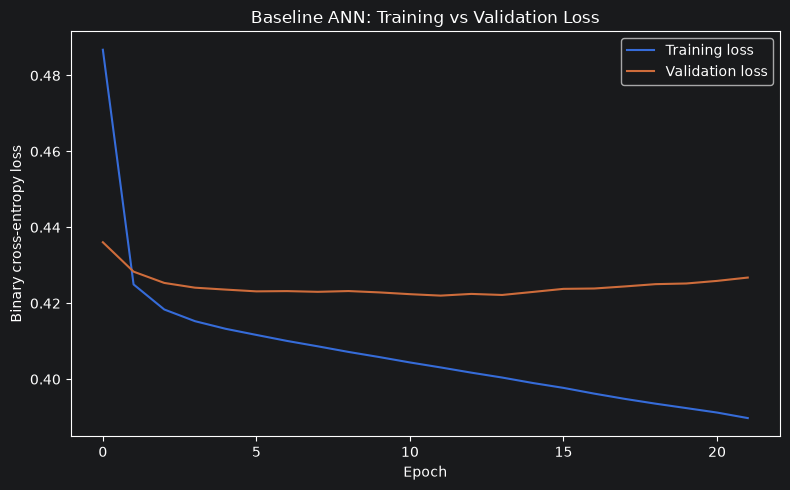

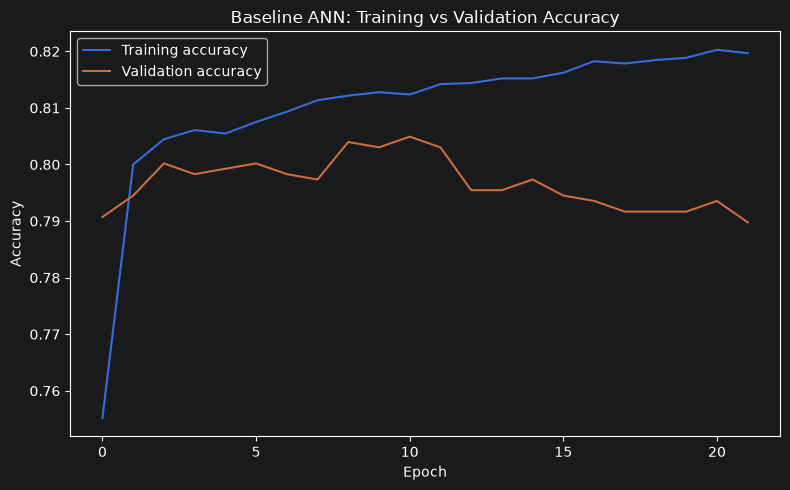

['baseline_results\\preprocessor.joblib']

In [87]:
from pathlib import Path

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_DIR / "baseline_metrics.json", "w") as file:
    json.dump(
        {key: float(value) for key, value in metrics.items()},
        file,
        indent=4
    )

pd.DataFrame(history.history).to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

model.save(OUTPUT_DIR / "baseline_ann.keras")


## PLOT TRAINING AND VALIDATION LOSS
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Baseline ANN: Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "baseline_loss.png", dpi=150)
plt.show()


## PLOT TRAINING AND VALIDATION ACCURACY
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline ANN: Training vs Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "baseline_accuracy.png", dpi=150)
plt.show()

## SAVE REPORTS TO MY PATH
with open(
    os.path.join(OUTPUT_DIR, "baseline_metrics.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        {
            "random_state": RANDOM_STATE,
            "epochs_executed": len(history.history["loss"]),
            "best_epoch": best_epoch,
            "threshold": 0.50,
            "test_metrics": {
                key: float(value)
                for key, value in metrics.items()
            }
        },
        file,
        indent=4
    )

report = classification_report(
    y_test_np,
    test_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
)

with open(
    os.path.join(OUTPUT_DIR, "classification_report.txt"),
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

pd.DataFrame({
    "actual_churn": y_test_np,
    "predicted_churn": test_predictions,
    "predicted_probability": test_probabilities
}).to_csv(
    os.path.join(OUTPUT_DIR, "test_predictions.csv"),
    index=False
)

# Save model and fitted preprocessing pipeline.
model.save(os.path.join(OUTPUT_DIR, "baseline_ann.keras"))
joblib.dump(
    preprocessor,
    os.path.join(OUTPUT_DIR, "preprocessor.joblib")
)



**INTERPRETATION OF LOSS CHART** - Training loss decreases: The network is learning patterns in the training dataset.
Validation loss increases: The model's predictions on unseen validation data are getting worse according to binary cross-entropy.
The gap widens: This divergence is a classic warning sign of overfitting. The model is fitting the training data without improving its ability to generalize
The validation loss appears lowest at the beginning of the plotted period and rises afterward. If these plotted values are the complete training history, the best validation-loss epoch may be the first epoch

**INTERPRETATION OF ACCURACY CHART** - Training accuracy increases overall, which is consistent with the model learning the training data.
Validation accuracy peaks around epoch 6, at approximately 80.7–80.8%, then falls slightly and remains relatively flat.
The gap between training and validation accuracy becomes more noticeable.
Accuracy alone may not tell the full story. A model can maintain similar accuracy while assigning increasingly poor probabilities to its predictions, which helps explain why validation loss can rise even when validation accuracy is relatively stable

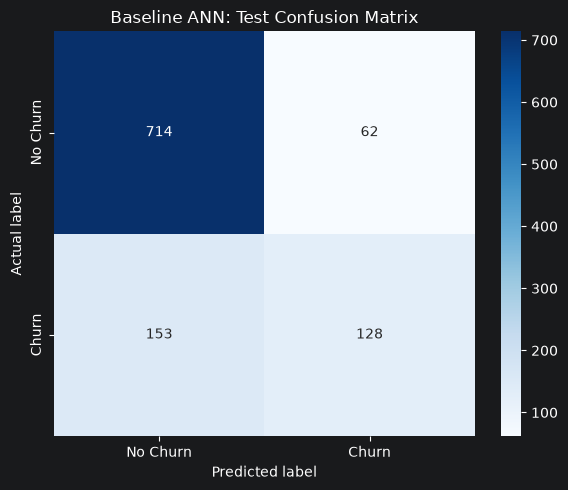


BASELINE EXPERIMENT COMPLETED


In [88]:
from pathlib import Path

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with open(OUTPUT_DIR / "baseline_metrics.json", "w") as file:
    json.dump(
        {key: float(value) for key, value in metrics.items()},
        file,
        indent=4
    )

pd.DataFrame(history.history).to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

model.save(OUTPUT_DIR / "baseline_ann.keras")


## CONFUSION MATRIX
cm = confusion_matrix(
    y_test_np, test_predictions, labels=[0, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title("Baseline ANN: Test Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nBASELINE EXPERIMENT COMPLETED")


**INTERPRETATION OF THE MATRIX** - True negatives (704): Correctly identified customers who did not churn.
False positives (72): Customers predicted to churn who actually did not churn.
**False negatives (144)**: Customers who actually churned but were incorrectly predicted not to churn.
True positives (137): Correctly identified customers who churned. The model is much better at identifying customers who will not churn than customers who will churn. For Otomoto's marketing segmentation, the main concern is the number of actual churners the model fails to identify

# STEP 9 - OVERALL ACCESSMENT OF THE EXISTING OTOMOTO ANN MODEL

## **Strengths**
- **Good discriminatory ability**: The ROC-AUC score indicates that the model can distinguish between customers who churn and those who remain reasonably well.
- **Effective identification of non-churners**: The classification report shows 91% recall for the No Churn class, indicating strong performance in identifying customers likely to remain.
- **Appropriate preprocessing**: Numerical standardization, categorical encoding and missing-value imputation prepare heterogeneous customer data for ANN training.
- **Controlled training**: Early stopping helps prevent unnecessary training and restores the weights associated with the best validation loss.
- **Reproducibility**: Fixed random seeds and a separate test set support consistent experimentation and fair evaluation.

## Weaknesses
- **Low churn recall**: At 48.75%, the model misses approximately half of actual churners, potentially limiting retention-campaign reach.
- **Moderate churn precision**: At 65.55%, approximately one-third of customers predicted to churn are false positives, which may lead to inefficient campaign spending.
- **Evidence of overfitting**: Training loss decreased from 0.4076 to 0.3969, while validation loss increased from approximately 0.4196 to 0.4237. This suggests that continued learning did not improve generalization.
- **Limited evidence of optimization**: The baseline uses one architecture and one primary configuration. Its performance does not establish whether alternative architectures, regularization methods or learning rates would perform better.
- **Potential business-objective mismatch**: Accuracy alone does not capture the relative costs of missing churners versus contacting customers who would not churn. The model's decision threshold should therefore be evaluated against Otomoto's retention objectives.

## Overall
The existing ANN provides a reasonable starting point for customer churn prediction, with nearly 80% test accuracy and a ROC-AUC above 0.84. Nevertheless, its weak churn recall and the divergence between training and validation loss indicate that further optimization is needed before relying on it for marketing decisions.

# STEP 10 - OPTIMISATION NEXT STEP

For Otomoto, the primary objective of ANN optimization is that marketing campaigns can identify more at-risk customers while controlling unnecessary campaign spending. The baseline model achieved 79.56% accuracy and 0.8407 ROC-AUC, but its churn recall was only 48.75%. Furthermore, the training history showed decreasing training loss alongside increasing validation loss, suggesting potential overfitting.
Based on these findings, the following optimization algorithms and techniques are recommended

## Selected Optimization Algorithms and Techniques
Based on Otomoto's baseline ANN results, I recommend the following optimization techniques:
- Adam (Adaptive Moment Estimation):
- RMSprop (Root Mean Square Propagation)
- SGD (Stochastic Gradient Descent)

## Justification
**- Adam (Adaptive Moment Estimation):** Selected as the baseline optimizer because it combines momentum-like gradient tracking with adaptive learning rates. It often trains neural networks efficiently with limited initial tuning, making it suitable for establishing baseline performance in Otomoto's churn prediction model.
**- RMSprop (Root Mean Square Propagation):** Selected because it adapts parameter updates using a moving average of squared gradients. It may improve training stability and predictive performance, helping Otomoto identify at-risk customers more efficiently.
**- SGD (Stochastic Gradient Descent):** Selected as a simple comparative optimizer. It provides a benchmark for assessing whether the adaptive mechanisms in Adam and RMSprop offer meaningful improvements in churn prediction, despite potentially requiring more training and careful learning-rate tuning.



# STEP 11 - OPTIMISATION

## Experiment - Compares Adam, RMSprop, and basic SGD using the same split,

TensorFlow version: 2.22.0-rc0
Train/validation/test: 4930 1056 1057
Encoded input features: 45

Training with Adam
Epoch 1/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7552 - auc: 0.7691 - loss: 0.4868 - val_accuracy: 0.7907 - val_auc: 0.8296 - val_loss: 0.4361
Epoch 2/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8000 - auc: 0.8382 - loss: 0.4250 - val_accuracy: 0.7945 - val_auc: 0.8358 - val_loss: 0.4283
Epoch 3/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8045 - auc: 0.8439 - loss: 0.4184 - val_accuracy: 0.8002 - val_auc: 0.8384 - val_loss: 0.4254
Epoch 4/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8061 - auc: 0.8465 - loss: 0.4153 - val_accuracy: 0.7983 - val_auc: 0.8395 - val_loss: 0.4241
Epoch 5/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8055 - auc: 0.8481 - loss: 0.4133 - val_accuracy: 0.7992 - val_auc: 0.8396 - val_loss: 0.4236
Epoch 6/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8075 - auc: 

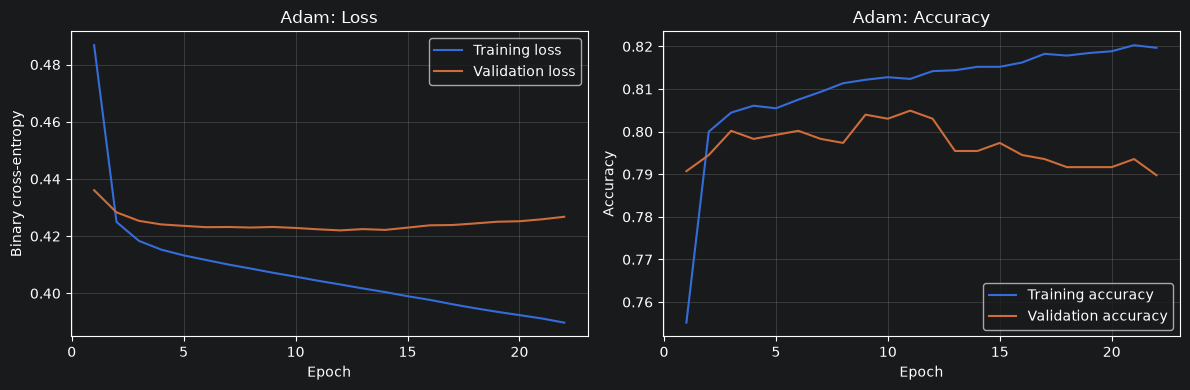


Training with RMSprop
Epoch 1/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7663 - auc: 0.7842 - loss: 0.4751 - val_accuracy: 0.7945 - val_auc: 0.8317 - val_loss: 0.4322
Epoch 2/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7996 - auc: 0.8387 - loss: 0.4243 - val_accuracy: 0.8002 - val_auc: 0.8387 - val_loss: 0.4249
Epoch 3/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8055 - auc: 0.8448 - loss: 0.4175 - val_accuracy: 0.7992 - val_auc: 0.8417 - val_loss: 0.4222
Epoch 4/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8063 - auc: 0.8477 - loss: 0.4140 - val_accuracy: 0.8021 - val_auc: 0.8427 - val_loss: 0.4208
Epoch 5/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8091 - auc: 0.8497 - loss: 0.4116 - val_accuracy: 0.8021 - val_auc: 0.8430 - val_loss: 0.4204
Epoch 6/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8085 - auc: 0.8510 - loss: 0.4099 - val_accuracy: 0.8021 - val_auc: 0.8433 - val_loss: 0.4204
Epoch 7/10

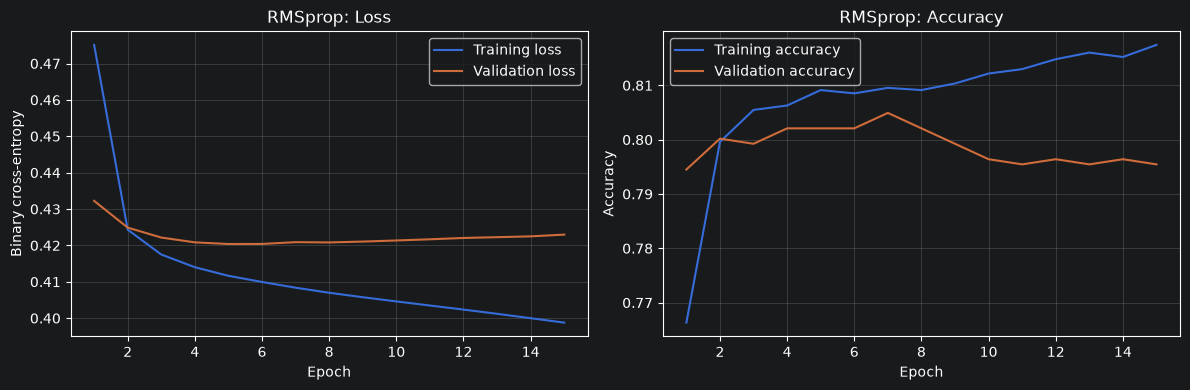


Training with SGD
Epoch 1/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5797 - auc: 0.4463 - loss: 0.6723 - val_accuracy: 0.6506 - val_auc: 0.4610 - val_loss: 0.6525
Epoch 2/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6799 - auc: 0.4967 - loss: 0.6338 - val_accuracy: 0.7074 - val_auc: 0.5095 - val_loss: 0.6214
Epoch 3/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7150 - auc: 0.5486 - loss: 0.6060 - val_accuracy: 0.7273 - val_auc: 0.5575 - val_loss: 0.5984
Epoch 4/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7304 - auc: 0.5949 - loss: 0.5851 - val_accuracy: 0.7292 - val_auc: 0.5994 - val_loss: 0.5805
Epoch 5/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7329 - auc: 0.6343 - loss: 0.5685 - val_accuracy: 0.7339 - val_auc: 0.6376 - val_loss: 0.5657
Epoch 6/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7335 - auc: 0.6675 - loss: 0.5547 - val_accuracy: 0.7358 - val_auc: 0.6685 - val_loss: 0.5531
Epoch 7/100
15

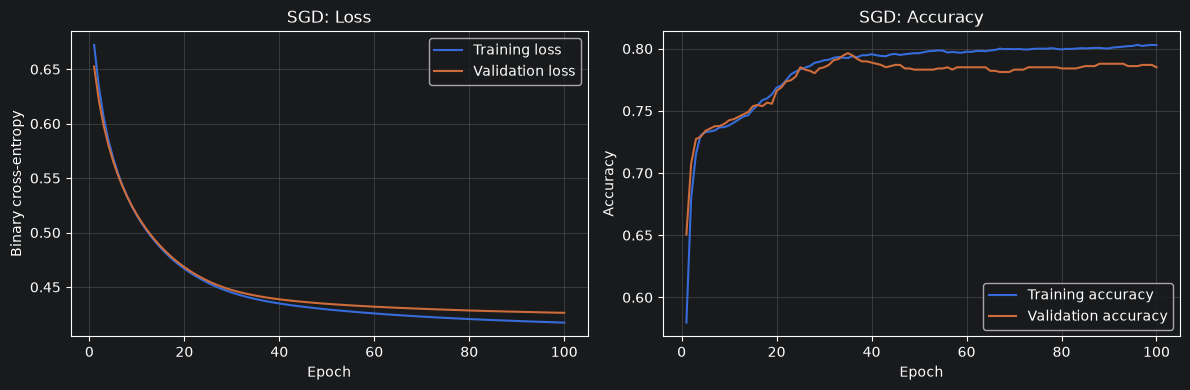


Validation metrics (use these to select the optimizer):


,accuracy,precision,recall,f1,roc_auc,pr_auc,epochs_trained
optimizer,,,,,,,
Adam,0.8030,0.6525,0.5500,0.5969,0.8413,0.6267,22
RMSprop,0.8021,0.6667,0.5071,0.5761,0.8431,0.6271,15
SGD,0.7850,0.6039,0.5500,0.5757,0.8372,0.6242,100



Test metrics (final comparison):


,accuracy,precision,recall,f1,roc_auc,pr_auc,epochs_trained
optimizer,,,,,,,
Adam,0.7966,0.6737,0.4555,0.5435,0.8403,0.6306,22
RMSprop,0.8070,0.7081,0.4662,0.5622,0.8449,0.6385,15
SGD,0.7994,0.6575,0.5125,0.5760,0.8412,0.6201,100



Saved all results to: C:\Users\Kayode Ogunyemi\PycharmProjects\WelcomeScreen\step_3a_optimizer_comparison
Files: ['adam_ann.keras', 'adam_classification_report.txt', 'adam_confusion_matrix.csv', 'adam_history.csv', 'adam_test_predictions.csv', 'adam_training_curves.png', 'all_optimizer_metrics.csv', 'optimizer_comparison_summary.json', 'preprocessor.joblib', 'rmsprop_ann.keras', 'rmsprop_classification_report.txt', 'rmsprop_confusion_matrix.csv', 'rmsprop_history.csv', 'rmsprop_test_predictions.csv', 'rmsprop_training_curves.png', 'sgd_ann.keras', 'sgd_classification_report.txt', 'sgd_confusion_matrix.csv', 'sgd_history.csv', 'sgd_test_predictions.csv', 'sgd_training_curves.png']


In [2]:
# Step 3: Apply Optimization Algorithms — Otomoto ANN
# Compares Adam, RMSprop, and basic SGD using the same split,
# preprocessing, ANN architecture, and evaluation threshold.

import json
import random
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score,
    precision_score, recall_score, roc_auc_score, confusion_matrix,
    classification_report
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


##### PARAMETERS
SEED = 42
DATASET_PATH = Path(r"C:\Users\Kayode Ogunyemi\Downloads\teleconnect.csv")
OUTPUT_DIR = Path("step_3a_optimizer_comparison")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
BATCH_SIZE = 32
PATIENCE = 10
THRESHOLD = 0.50
LEARNING_RATE = 0.001

def reset_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

reset_seeds()
print("TensorFlow version:", tf.__version__)


######### INGEST DATASET AND PREPARE data
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_PATH}. Update DATASET_PATH to your local file."
    )

df = pd.read_csv(DATASET_PATH)
if "Churn" not in df.columns:
    raise ValueError("Expected target column 'Churn' was not found.")

df = df.copy()
if "customerID" in df.columns:
    df.drop(columns=["customerID"], inplace=True)
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

target_text = df["Churn"].astype(str).str.strip().str.lower()
y = target_text.map({"yes": 1, "no": 0, "1": 1, "0": 0})
if y.isna().any():
    raise ValueError(f"Unexpected Churn labels: {sorted(target_text[y.isna()].unique().tolist())}")

X = df.drop(columns=["Churn"])
y = y.astype("int32")

# Same stratified 70/15/15 split for every optimizer.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)







#### PRE_PROCESSING; FIT ONLY ON TRAINING DATA #########

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", onehot),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
], remainder="drop")

X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_val_p = preprocessor.transform(X_val).astype("float32")
X_test_p = preprocessor.transform(X_test).astype("float32")

y_train_np = y_train.to_numpy(dtype="float32")
y_val_np = y_val.to_numpy(dtype="float32")
y_test_np = y_test.to_numpy(dtype="int32")

print("Train/validation/test:", len(X_train), len(X_val), len(X_test))
print("Encoded input features:", X_train_p.shape[1])








##### BUILD THE SAME ANN FOR EACH OPTIMIZER ( ADAM, RMSPROP & SGD ) ##########
def build_model(optimizer_name):
    tf.keras.backend.clear_session()
    reset_seeds()

    if optimizer_name == "Adam":
        optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE)
    elif optimizer_name == "RMSprop":
        optimizer = tf.keras.optimizers.RMSprop(
            learning_rate=LEARNING_RATE, rho=0.9
        )
    elif optimizer_name == "SGD":
        # Basic SGD, intentionally without momentum for the initial comparison.
        optimizer = tf.keras.optimizers.SGD(learning_rate=LEARNING_RATE)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train_p.shape[1],)),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc"),
        ],
    )
    return model




##### TRAIN AND EVALUATE EACH OPTIMIZER ####################
optimizer_names = ["Adam", "RMSprop", "SGD"]
all_metrics = []
all_histories = {}
trained_models = {}

def calculate_metrics(y_true, probabilities, split_name):
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities).ravel()
    predictions = (probabilities >= THRESHOLD).astype(int)
    return {
        "split": split_name,
        "threshold": THRESHOLD,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
    }, predictions

for optimizer_name in optimizer_names:
    print(f"\n{'=' * 60}\nTraining with {optimizer_name}\n{'=' * 60}")

    model = build_model(optimizer_name)
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        verbose=1,
    )

    history = model.fit(
        X_train_p, y_train_np,
        validation_data=(X_val_p, y_val_np),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        verbose=1,
    )

    history_df = pd.DataFrame(history.history)
    history_df.index = np.arange(1, len(history_df) + 1)
    history_df.index.name = "epoch"
    all_histories[optimizer_name] = history_df
    trained_models[optimizer_name] = model

    val_prob = model.predict(X_val_p, verbose=0).ravel()
    test_prob = model.predict(X_test_p, verbose=0).ravel()

    val_metrics, _ = calculate_metrics(y_val_np, val_prob, "Validation")
    test_metrics, test_pred = calculate_metrics(y_test_np, test_prob, "Test")

    for metrics in (val_metrics, test_metrics):
        metrics["optimizer"] = optimizer_name
        metrics["epochs_trained"] = len(history_df)
        all_metrics.append(metrics)

    # Save per-optimizer history, predictions, confusion matrix, report and model.
    history_df.to_csv(OUTPUT_DIR / f"{optimizer_name.lower()}_history.csv")

    cm = confusion_matrix(y_test_np, test_pred, labels=[0, 1])
    pd.DataFrame(
        cm,
        index=["Actual No Churn", "Actual Churn"],
        columns=["Predicted No Churn", "Predicted Churn"],
    ).to_csv(OUTPUT_DIR / f"{optimizer_name.lower()}_confusion_matrix.csv")

    report = classification_report(
        y_test_np, test_pred, labels=[0, 1],
        target_names=["No Churn", "Churn"], digits=4, zero_division=0,
    )
    (OUTPUT_DIR / f"{optimizer_name.lower()}_classification_report.txt").write_text(
        report, encoding="utf-8"
    )

    pd.DataFrame({
        "actual_churn": y_test_np,
        "churn_probability": test_prob,
        "predicted_churn": test_pred,
    }).to_csv(OUTPUT_DIR / f"{optimizer_name.lower()}_test_predictions.csv", index=False)

    model.save(OUTPUT_DIR / f"{optimizer_name.lower()}_ann.keras")

    # Plot loss and accuracy for this optimizer
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Loss plot
    axes[0].plot(history_df.index, history_df["loss"], label="Training loss")
    axes[0].plot(history_df.index, history_df["val_loss"], label="Validation loss")
    axes[0].set(title=f"{optimizer_name}: Loss", xlabel="Epoch", ylabel="Binary cross-entropy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Accuracy plot
    axes[1].plot(history_df.index, history_df["accuracy"], label="Training accuracy")
    axes[1].plot(history_df.index, history_df["val_accuracy"], label="Validation accuracy")
    axes[1].set(title=f"{optimizer_name}: Accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{optimizer_name.lower()}_training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)









######## COMPARE RESULTS AND SAVE VISUALS #####################
metrics_df = pd.DataFrame(all_metrics)
metrics_df.to_csv(OUTPUT_DIR / "all_optimizer_metrics.csv", index=False)

validation_results = metrics_df[metrics_df["split"] == "Validation"].copy()
test_results = metrics_df[metrics_df["split"] == "Test"].copy()

print("\nValidation metrics (use these to select the optimizer):")
display(validation_results.set_index("optimizer")[
    ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "epochs_trained"]
].round(4))

print("\nTest metrics (final comparison):")
display(test_results.set_index("optimizer")[
    ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "epochs_trained"]
].round(4))

# Save the preprocessing pipeline used for all three models.
joblib.dump(preprocessor, OUTPUT_DIR / "preprocessor.joblib")

summary = {
    "experiment": "Step 3 — Optimizer comparison",
    "seed": SEED,
    "dataset": str(DATASET_PATH),
    "architecture": [32, 16, 1],
    "train_validation_test_split": [0.70, 0.15, 0.15],
    "batch_size": BATCH_SIZE,
    "max_epochs": EPOCHS,
    "early_stopping_patience": PATIENCE,
    "threshold": THRESHOLD,
    "learning_rate": LEARNING_RATE,
    "optimizers": {
        "Adam": "Adam(learning_rate=0.001)",
        "RMSprop": "RMSprop(learning_rate=0.001, rho=0.9)",
        "SGD": "SGD(learning_rate=0.001, no momentum)",
    },
    "metrics": all_metrics,
}
with open(OUTPUT_DIR / "optimizer_comparison_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\nSaved all results to:", OUTPUT_DIR.resolve())
print("Files:", sorted(p.name for p in OUTPUT_DIR.iterdir()))